In [67]:
import requests
import pandas as pd
from bs4 import BeautifulSoup
from shapely.geometry import Point
import geopandas
import matplotlib.pyplot as plt
import json
import os

In [68]:
paradisec = 'https://catalog.paradisec.org.au/collections/search'

In [69]:
html_content = requests.get(paradisec).content

soup = BeautifulSoup(html_content, 'html.parser')

In [70]:
a_tags = soup.find_all('a')

In [71]:
paradisec_languages = [a_tag.text.strip() for a_tag in a_tags]

In [72]:
len(paradisec_languages)

336

In [73]:
glottolog_data = pd.read_csv('languages_and_dialects_geo.csv')

In [74]:
df_filtered = glottolog_data[glottolog_data['name'].isin(paradisec_languages)]

In [75]:
df_filtered

,glottocode,name,isocodes,level,macroarea,latitude,longitude
63,abui1241,Abui,abz,language,Papunesia,-8.31058,124.58800
503,amar1273,Amarasi,aaz,language,Papunesia,-10.21751,123.96373
647,anei1239,Aneityum,aty,language,Papunesia,-20.18640,169.82500
678,ango1255,Angoram,aog,language,Papunesia,-4.07758,144.02800
917,aros1241,Arosi,aia,language,Papunesia,-10.24410,161.43200
...,...,...,...,...,...,...,...
20301,vari1239,Varisi,vrs,language,Papunesia,-6.83443,156.65500
20495,nucl1620,Wahgi,wgi,language,Papunesia,-6.11629,144.66500
20570,walm1242,Walmajarri,NaN,dialect,Australia,NaN,NaN
20697,warl1254,Warlpiri,wbp,language,Australia,-20.10080,131.05000


In [76]:
points = df_filtered.apply(lambda r: Point(r.longitude, r.latitude), axis=1)
gdb = geopandas.GeoDataFrame(df_filtered.assign(geometry=points), \
                        crs={'init' :'epsg:4326'})
xys = gdb['geometry'].apply(lambda pt: pd.Series({'x': pt.x, 'y': pt.y}))
gdb['x'] = xys['x']
gdb['y'] = xys['y']

/Users/go202/anaconda3/envs/eq_pap_1/lib/python3.12/site-packages/pyproj/crs/crs.py:141: FutureWarning: '+init=<authority>:<code>' syntax is deprecated. '<authority>:<code>' is the preferred initialization method. When making the change, be mindful of axis order changes: https://pyproj4.github.io/pyproj/stable/gotchas.html#axis-order-changes-in-proj-6
  in_crs_string = _prepare_from_proj_string(in_crs_string)


In [77]:
worldmap = geopandas.read_file(geopandas.datasets.get_path("naturalearth_lowres"))

/var/folders/hw/3z11r39j0gd4kgzxbjj6v8z80000gp/T/ipykernel_36371/867032107.py:1: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  worldmap = geopandas.read_file(geopandas.datasets.get_path("naturalearth_lowres"))


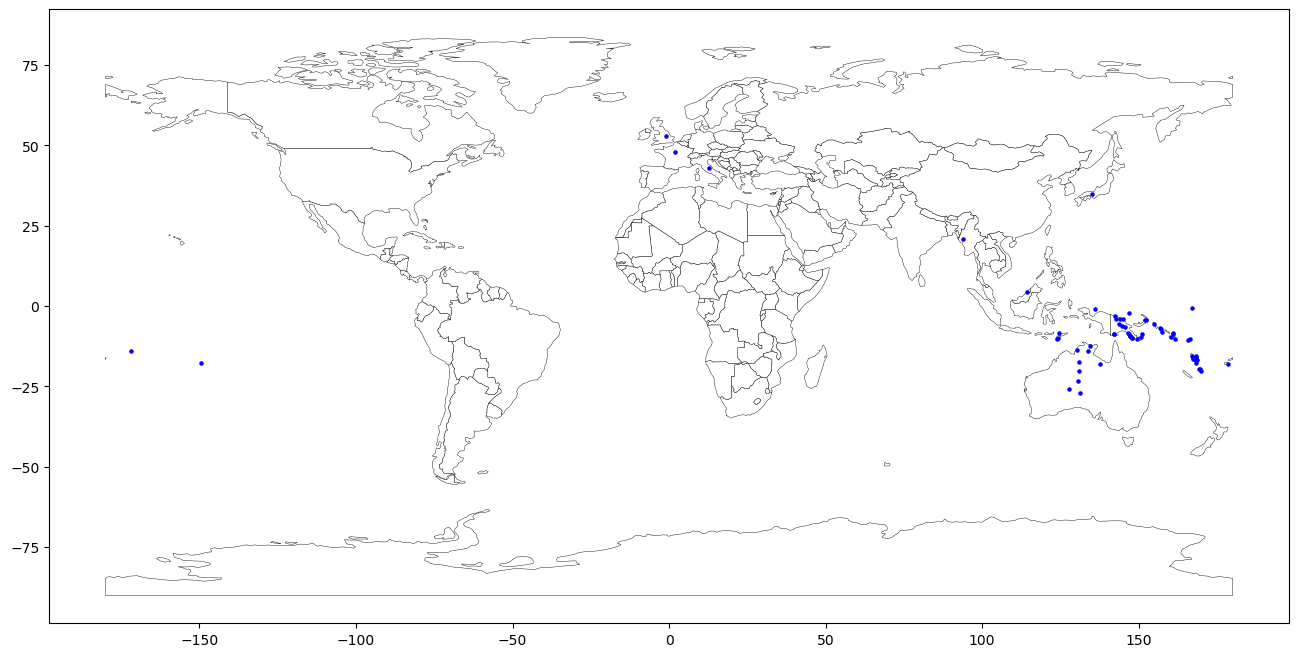

In [78]:
fig, ax = plt.subplots(figsize=(16, 10))
worldmap.plot(color="white", edgecolor = 'black',ax=ax, linewidth=0.3)
gdb.plot(ax=ax, color = 'blue', markersize = 5)
plt.show()

# Size extraction

In [79]:
graphql_query = """{
  items(limit: 100, page: 2) {
    total
    next_page
    results {
      full_identifier
      title
      description
      dialect
      language
      region
      originated_on
      essences_count
      essences {
        id   
        filename
        duration
        bitrate:bitrate
        samplerate
        itemId
        mimetype
        updatedAt
        fps
      }
      originated_on_narrative
      collection {
        identifier
        title
      }
      collector {
        first_name
        last_name
        country
      }
      university {
        name
        party_identifier
      }
      discourse_type {
        name
      }
      data_types {
        name
      }
      data_categories {
        name
      }
      countries {
        name
        code
      }
      subject_languages {
        name
        code
      }
      content_languages {
        name
        code
      }
      access_class
      access_narrative
      citation
      ingest_notes
      original_media
      permalink
      doi
    }
  }
}"""



In [80]:
headers = {
    "User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10.15; rv:124.0) Gecko/20100101 Firefox/124.0",
    "Accept": "*/*",
    "Accept-Language": "en-GB,en;q=0.5",
    "Accept-Encoding": "gzip, deflate, br",
    "Referer": "https://catalog.paradisec.org.au/graphiql",
    "Content-Type": "application/json",
    "X-CSRF-Token": "WMRdCmarai5DfoZrbM1MdTJtYh-7kx73DPKGr5cgNJn9R9JahgbhsScC4IG4UteTSgmpp-x2AtySU2w1pesaqA",
    "Origin": "https://catalog.paradisec.org.au",
    "Connection": "keep-alive",
    "Cookie": "_ga_X7RT9Y7NXS=GS1.1.1711475412.8.1.1711475953.0.0.0; _ga=GA1.3.1409180406.1711383017; _gid=GA1.3.1117965470.1711383018; _nabu_session=Na1v8PMml3%2BaGb4qjxRi%2F4WaI4jcFeTm5ocIlTaaHagMuZj6ht4mjqUHJ4IFdxyiT3yxy54umIUjL2b9P0UKThudJJEgSdtNXBH4SRcrepdPtCvWoCnSkmsKuk8v7gxcRIMyztcZgIyeKFUxtuMFEU20UIJJSqxucf%2FsFy5W2%2BXOoYHRhT8fCmbSabIyWkmcVkxJyldWcEMWGS4RSNXIAdV3KnEUjVztNjMuNSqFkDj0LJ17q0IDWsUEI7FKiuZ%2BRMobigJbxBr1h3i6Y6oY6Rst0GxzBB%2BAkAfkM2z2K%2FmKSFPql11%2Bk2xkpLwmOPU7yaJfypxMWTyO0EOrVz9UY2cEez90LduZxpB2QZuV7PZFIohwFmpG0FoMUvhpULJpPOn3GPGbaqQA1b23IKKHTFvPL2YAnsT%2Bf5JqP49rQTFyYidzLDTV6giLFLQzyPxJnsMvrv%2B2cqKRCHspqkCtYmNzLAsCCFksMFgLJYHKKkDv%2FGII3B9qFy0LuxDePyUa5WQNqkve6rz1l%2BskpXHOjr2Mj8KY7oROuvay61U139mcGznNEAA8scjdNH6WY%2Bi3Cf4V%2BNLR2lnWDJGObOwP2pU%2FR5W7KYUWK9UnacP7VJN9%2BMG%2FFCMIXjH9MWP2X87wYOatlGaaF2Y4lRzS6vTlFE8zY74LUH9Skwdl669INJfuZcvocxYJ7DA4F6mWyAkirEl%2F6aq%2F2b9E--QlwX8pBq%2FxmRznVV--Z4LJfJGbMFTJNgy%2F5Mjc8w%3D%3D",
    "Sec-Fetch-Dest": "empty",
    "Sec-Fetch-Mode": "cors",
    "Sec-Fetch-Site": "same-origin",
    "TE": "trailers"
}


In [81]:
url = 'https://catalog.paradisec.org.au/graphiql'

In [82]:

response = requests.post(url=url, json=graphql_query, headers=headers)

In [83]:
response

<Response [404]>

In [84]:
tr = response.json()

JSONDecodeError: Expecting value: line 1 column 1 (char 0)

In [ ]:
def run_query(query, headers=None): # A simple function to use requests.post to make the API call. Note the json= section.
    if headers is None:
        headers = {}
    request = requests.post('https://catalog.paradisec.org.au/graphiql', json={'query': query}, headers=headers)
    if request.status_code == 200:
        return request.json()
    else:
        raise Exception("Query failed to run by returning code of {}. {}".format(request.status_code, query))

In [ ]:
request = requests.post('https://catalog.paradisec.org.au/graphiql', json={'query': graphql_query}, headers = headers)

In [ ]:
request

<Response [404]>

In [ ]:
result = run_query(graphql_query)

Exception: Query failed to run by returning code of 404. {
  items(limit: 100, page: 2) {
    total
    next_page
    results {
      full_identifier
      title
      description
      dialect
      language
      region
      originated_on
      essences_count
      essences {
        id   
        filename
        duration
        bitrate:bitrate
        samplerate
        itemId
        mimetype
        updatedAt
        fps
      }
      originated_on_narrative
      collection {
        identifier
        title
      }
      collector {
        first_name
        last_name
        country
      }
      university {
        name
        party_identifier
      }
      discourse_type {
        name
      }
      data_types {
        name
      }
      data_categories {
        name
      }
      countries {
        name
        code
      }
      subject_languages {
        name
        code
      }
      content_languages {
        name
        code
      }
      access_class
     

In [ ]:
url = 'https://catalog.paradisec.org.au/graphiql'  # Replace 'example.com/graphql' with your actual GraphQL endpoint

# Define the query
query = {
    "query": """
        {
          items(limit: 10000, page: 5) {
            total
            next_page
            results {
              full_identifier
              title
              description
              dialect
              language
              region
              originated_on
              essences_count
              essences {
                id
                filename
                duration
                bitrate: bitrate
                samplerate
                itemId
                mimetype
                updatedAt
                fps
              }
              originated_on_narrative
              collection {
                identifier
                title
              }
              collector {
                first_name
                last_name
                country
              }
              countries {
                name
                code
              }
              subject_languages {
                name
                code
              }
              content_languages {
                name
                code
              }
            }
          }
        }
    """
}

# Send the HTTP request
response = requests.post(url, json=query)

In [ ]:
response

<Response [404]>

In [ ]:
tr

b'<!DOCTYPE html>\n<html data-turbo="false">\n<head>\n<script src="https://www.googletagmanager.com/gtag/js?id=UA-36256674-1" async="async"></script>\n<script>\n  window.dataLayer = window.dataLayer || [];\n  function gtag(){dataLayer.push(arguments);}\n  gtag(\'js\', new Date());\n  \n  gtag(\'config\', \'UA-36256674-1\');\n</script>\n<script>\n  const calendarImagePath = "/assets/calendar-d5c51e197c3a7c2bb8a45632329bd711834f398720665eb0d18dad6bad324262.png";\n</script>\n<title>Nabu - Home</title>\n<meta content="width=device-width,initial-scale=1" name="viewport">\n<meta content="reload" name="turbo-visit-control">\n<meta name="csrf-param" content="authenticity_token" />\n<meta name="csrf-token" content="NiuSkCb9cnqbjFH5N1KoIWx17VsrUSdv98mPlMVt_nzYgxHSIKuhXeNQbFNNofAGbRkwxxEdJnr1SjsOfXPlAw" />\n<link rel="stylesheet" href="/assets/application-f189b4affc5b147f8f8e8803765c189f66e289645f991bcdebb6045f1b7718b1.css" data-turbo-track="reload" />\n<script type="importmap" data-turbo-track="

In [ ]:
type(graphql_query)

str

In [ ]:
my_json = response.content.decode('utf8').replace("'", '"')

In [ ]:
my_json

'type AccessCondition {\n  collections: [Collection]\n  items: [Item]\n  name: String\n}\n\ntype Agent {\n  role_name: String\n  user: Person\n  user_name: String\n}\n\ntype Boundary {\n  east_limit: Float!\n  north_limit: Float!\n  south_limit: Float!\n  west_limit: Float!\n}\n\ntype Collection {\n  access_class: String\n  access_narrative: String\n  boundaries: Boundary\n  citation: String\n  collector: Person\n  comments: String\n  complete: Boolean\n  content_languages: [Language]\n  countries: [Country]\n  description: String\n  doi: String\n  doi_xml: String\n  field_of_research: FieldOfResearch\n  grants: [Grant]\n  id: ID!\n  identifier: String!\n  media: String\n  metadata_source: String\n  operator: Person\n  orthographic_notes: String\n  permalink: String!\n  region: String\n  subject_languages: [Language]\n  tape_location: Boolean\n  title: String!\n  university: University\n}\n\ntype Country {\n  boundaries: [Boundary]\n  code: String!\n  id: ID!\n  languages: [Language]\n

# get subject languages name and code

In [ ]:
with open('paradisec.json', 'r') as file:
    # Load JSON data from the file
    data = json.load(file)

In [ ]:
data

{'data': {'items': {'total': 33036,
   'next_page': 2,
   'results': [{'full_identifier': 'AA1-001',
     'title': 'Pak Nongeng tells about the first four people, food taboos, and various other topics',
     'description': 'Pak Nongeng tells about the first four people, food taboos, and various other topics',
     'dialect': None,
     'language': 'Salako, Badamea',
     'region': 'Sasak village, Samalantan, Sambas Regency, West Kalimantan',
     'originated_on': '1987-11-17',
     'essences_count': 4,
     'essences': [{'id': '967948',
       'filename': 'AA1-001-A.mp3',
       'duration': 2992.85,
       'bitrate': 128001,
       'samplerate': 48000,
       'itemId': 1,
       'mimetype': 'audio/mpeg',
       'updatedAt': '2016-05-04T09:21:10+10:00',
       'fps': None,
       'size': '47886080'},
      {'id': '967947',
       'filename': 'AA1-001-A.wav',
       'duration': 2992.81,
       'bitrate': 2304694,
       'samplerate': 48000,
       'itemId': 1,
       'mimetype': 'audio/v

In [ ]:
folder_path = '/Users/go202/Desktop/EQUATE/paradisec_data'

In [ ]:
# Initialize empty lists to store data
rows = []


for filename in os.listdir(folder_path):
    if filename.startswith('paradisec') and filename.endswith('.json'):
        file_path = os.path.join(folder_path, filename)
        with open(file_path, 'r') as file:
            # Load JSON data from the file
            data = json.load(file)
# Extract data from each result
        for result in data['data']['items']['results']:
            sizes = []
            subject_language_names = []
            subject_language_codes = []
            content_language_names = []
            content_language_codes = []
            
            # Extract size
            for essence in result['essences']:
                sizes.append(int(essence['size']))
            
            # Extract subject languages
            for subject_language in result['subject_languages']:
                subject_language_names.append(subject_language['name'])
                subject_language_codes.append(subject_language['code'])
            
            # Extract content languages
            for content_language in result['content_languages']:
                content_language_names.append(content_language['name'])
                content_language_codes.append(content_language['code'])

            # Add extracted data to rows list
            rows.append({
                'Size': sizes,
                'Subject Language Name': subject_language_names,
                'Subject Language Code': subject_language_codes,
                'Content Language Name': content_language_names,
                'Content Language Code': content_language_codes
            })

        # Create DataFrame
        df = pd.DataFrame(rows)

        # Display DataFrame
        print(df)

                                              Size  \
0             [1756960, 1686321, 1664560, 1596498]   
1                                        [1322052]   
2    [1448466, 1517015, 1753319, 1781204, 1710219]   
3                      [1728784, 1854135, 1783518]   
4                      [1154361, 1560882, 1379501]   
..                                             ...   
495                        [246941223, 3978169216]   
496   [27718, 1964504, 9453696, 190077, 340513280]   
497                         [28083590, 1154825896]   
498  [20199, 1387072, 14641280, 138011, 527264132]   
499                        [148352797, 2131884248]   

                Subject Language Name Subject Language Code  \
0                           [Lenakel]                 [tnl]   
1               [Lenakel, Whitesands]            [tnl, tnp]   
2             [Undetermined language]                 [und]   
3                           [Lenakel]                 [tnl]   
4                             [Paama

In [ ]:
df

,Size,Subject Language Name,Subject Language Code,Content Language Name,Content Language Code
0,"[1756960, 1686321, 1664560, 1596498]",[Lenakel],[tnl],[Lenakel],[tnl]
1,[1322052],"[Lenakel, Whitesands]","[tnl, tnp]","[Lenakel, Whitesands]","[tnl, tnp]"
2,"[1448466, 1517015, 1753319, 1781204, 1710219]",[Undetermined language],[und],[Undetermined language],[und]
3,"[1728784, 1854135, 1783518]",[Lenakel],[tnl],[Lenakel],[tnl]
4,"[1154361, 1560882, 1379501]",[Paama],[pma],[Paama],[pma]
...,...,...,...,...,...
1995,"[3055744, 110456806, 2078848, 75164302, 103521...",[Pawaia],[pwa],[Pawaia],[pwa]
1996,"[2365568, 85507924, 2293888, 82960084, 117865,...",[Purari],[iar],[Purari],[iar]
1997,"[3416192, 123398320, 6967424, 251525500, 11486...","[Dobu, Motu, Waima]","[dob, meu, rro]","[Dobu, Motu, Waima]","[dob, meu, rro]"
1998,"[2506880, 90544606, 2066560, 74681050, 102020,...","[Kiwai, Southern, Kuanua, Motu]","[kjd, ksd, meu]","[Kiwai, Southern, Kuanua, Motu]","[kjd, ksd, meu]"


In [87]:
df['Subject Language Name'] = df['Subject Language Name'].apply(lambda x: ', '.join(x))

In [85]:
df['Subject Language Code'] = df['Subject Language Code'].apply(lambda x: ', '.join(x))

In [89]:
df['Size'] = df['Size'].apply(lambda x: sum(x))

In [90]:
df

,Size,Subject Language Name,Subject Language Code,Content Language Name,Content Language Code
0,6704339,Lenakel,tnl,[Lenakel],[tnl]
1,1322052,"Lenakel, Whitesands","tnl, tnp","[Lenakel, Whitesands]","[tnl, tnp]"
2,8210223,Undetermined language,und,[Undetermined language],[und]
3,5366437,Lenakel,tnl,[Lenakel],[tnl]
4,4094744,Paama,pma,[Paama],[pma]
...,...,...,...,...,...
1995,194444737,Pawaia,pwa,[Pawaia],[pwa]
1996,176914423,Purari,iar,[Purari],[iar]
1997,388881717,"Dobu, Motu, Waima","dob, meu, rro","[Dobu, Motu, Waima]","[dob, meu, rro]"
1998,173502322,"Kiwai, Southern, Kuanua, Motu","kjd, ksd, meu","[Kiwai, Southern, Kuanua, Motu]","[kjd, ksd, meu]"


In [91]:
summed_df = df.groupby(['Subject Language Name', 'Subject Language Code'])['Size'].sum().reset_index()

In [52]:
summed_df = df.groupby(['Subject Language Name'])['Size'].sum().reset_index()

In [92]:
summed_df

,Subject Language Name,Subject Language Code,Size
0,,,13059031379
1,'Are'are,alu,85545902
2,"'Are'are, Babatana, Lau, To'abaita, Ontong Java","alu, baa, llu, mlu, ojv",221211658
3,"'Are'are, Naasioi","alu, nas",27807665
4,"'Are'are, Sa'a, Ghari","alu, apb, gri",3867336
...,...,...,...
607,"Zabana, Kwara'ae, Gela, Pijin, Roviana","kji, kwf, nlg, pis, rug",278063296
608,"Zia, Undetermined language","zia, und",3848712
609,Zulu,zul,1379673
610,Äiwoo,nfl,92063897


In [93]:
summed_df['Size'] = summed_df['Size'] / (1024 ** 3)

In [94]:
df_sorted = summed_df.sort_values(by='Size', ascending=False)

In [95]:
df_sorted

,Subject Language Name,Subject Language Code,Size
166,"Chinese, Mandarin, Chinese, Yue, Undetermined ...","cmn, yue, und",2230.531271
432,"Naga, Sumi",nsm,498.469245
254,"Gurinji, Kriol, Gurindji Kriol","gue, rop, gjr",248.712084
253,Gurindji Kriol,gjr,74.327696
225,Fijian,fij,67.768092
...,...,...,...
348,"Lenakel, Whitesands","tnl, tnp",0.001231
472,"Petats, Teop","pex, tio",0.001221
87,"Axamb, Rerep, Uripiv-Wala-Rano-Atchin","ahb, pgk, upv",0.001196
26,"Ambrym, North",mmg,0.001153


In [96]:
df_sorted.to_excel("paradisec.xlsx")  


In [9]:
Language = []
Size = []

In [25]:
languages = []
sizes = []

for result in data['data']['items']['results']:
    # Check if 'essences' list is not empty
    if result['essences']:
        # Extract language and size from each result and append to the lists
        languages.append(result['language'])
        sizes.append(result['essences'][0]['size'])


In [26]:
df = pd.DataFrame({'Language': languages, 'Size': sizes})

In [27]:
df

,Language,Size
0,"Salako, Badamea",47886080
1,Selako,30497408
2,Selako,86130560
3,Selako,30497408
4,Selako,30371456
...,...,...
492,Pavaia (alt. name),3055744
493,Koriki (alt. name),2365568
494,Roro (as an alt. name for Waima),3416192
495,"Kuanua, C[oastal] Kiwai, Motu",2506880


In [15]:
aggregated_df = df.groupby('Language').sum().reset_index()

In [16]:
aggregated_df

,Language,Size
0,"Abkhaz, Circassian",31621248
1,"Aitutake, Atiu, Rarotonga, Pakapuka, Uvea, Man...",28882
2,Altaic,93139072
3,Amarasi,5933951835530856938626218452541312605523220083...
4,"Aneityum, Kwamera, Lenakel, East Tanna, White ...",20557952
...,...,...
140,"White Miao, Blue Miao",5243
141,Xhosa,3279288
142,"Xhosa, Sindabele, Kalangga, Ilung Bushman",6882585
143,"Yele, Irish, Japanese, Malay, Afrikaans",69879


In [22]:
df

,Language,Size
0,"Abkhaz, Circassian",31621248
1,"Aitutake, Atiu, Rarotonga, Pakapuka, Uvea, Man...",28882
2,Altaic,93139072
3,Amarasi,5933951835530856938626218452541312605523220083...
4,"Aneityum, Kwamera, Lenakel, East Tanna, White ...",20557952
...,...,...
140,"White Miao, Blue Miao",5243
141,Xhosa,3279288
142,"Xhosa, Sindabele, Kalangga, Ilung Bushman",6882585
143,"Yele, Irish, Japanese, Malay, Afrikaans",69879


In [20]:
aggregated_df.to_csv('paradisec.csv', index=False)